Task 1: Temperature
First request the daily mean air temperture for all of 2025.
The specifications you will need for this is:
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850',
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2025-12-31',
}
Otherwise you can follow the example from frost.met.no on how to get the data
when using Python
10/3/26, 10:54 AM deliverable_1
file:///C:/Users/tutor5923/Documents/inf201-h26-my-repo/deliverables/deliverable_1/deliverable_1.html 1/3
Make a nicely formatted plot of this air temperature, where time is on the x-axis and
temperature is on the y-axis
Create a nicely formatted summary table containing mean, median, min and max
temperature for this year, and display it with print()

5fc771f3-aa29-4adb-bd94-b8415d6cb421
   max_temp  min_temp  mean_temp  median_temp
0      24.5     -16.1   7.903571         8.35


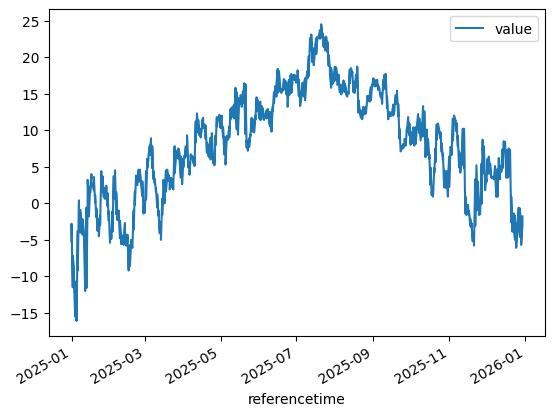

In [219]:
import requests
import os
import pandas as pd
import json
from dotenv import load_dotenv

load_dotenv()
client_id = os.getenv("client_id")
print(client_id)

endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

frost_response = requests.get(endpoint, parameters, auth=(client_id, ""))
json_data = frost_response.json()
data = json_data["data"]

# print(json.dumps(json_data, indent=4))

values = pd.DataFrame()

frames = []
for e in range(len(data)):
    row = pd.DataFrame(data[e]["observations"])
    row["referencetime"] = pd.to_datetime(data[e]["referenceTime"])
    row["sources"] = data[e]["sourceId"]
    frames.append(row)
values = pd.concat(frames, ignore_index=True)
# print(values)

# values.plot()
values.plot(x="referencetime", y="value")


df = pd.DataFrame(
    columns=["max_temp", "min_temp", "mean_temp", "median_temp"],
    data=[[values["value"].max(), values["value"].min(), values["value"].mean(), values["value"].median()]]
)

print(df)


Task 2: Precipitation
Request data for precipitation for the same time period, specifically measurements
of precipitation over 24 hours. This is coded as sum(precipitation_amount
P1D) in the database
Create a new plot that shows both the temperature from task 1 and the precipitation
in the same plot
Think through how to display both values in a way that is useful and looks good
Consider which type of plot works best for each measurement (scatter, line, bar,
pie chart, ...?)

Text(0, 0.5, 'mean temperature (Celsius)')

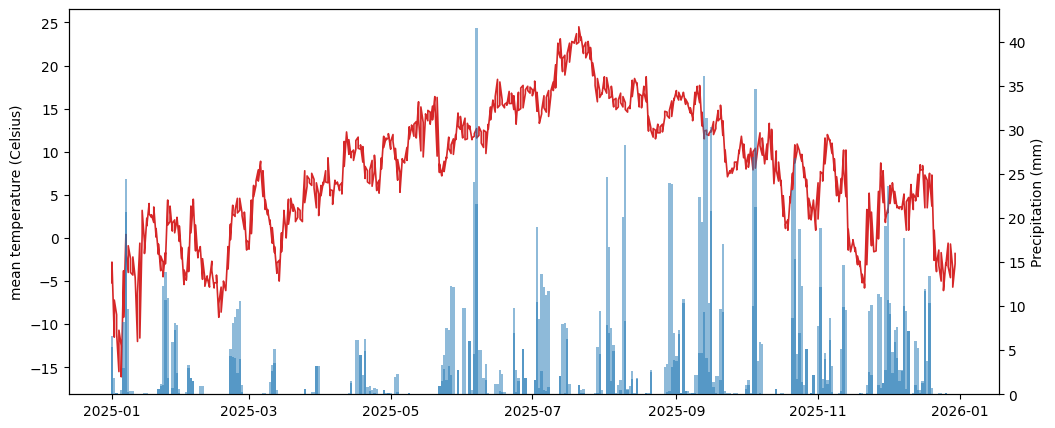

In [ ]:
import datetime as dt

import matplotlib.pyplot as plt


endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters_precip = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

precip_response = requests.get(endpoint, parameters_precip, auth=(client_id, ""))
json_data_precip = precip_response.json()
data_precip = json_data_precip["data"]

# print(json.dumps(json_data_precip, indent=4))

values_precip = pd.DataFrame()

fig, ax = plt.subplots(figsize=(12, 5))

frames_historic = []
for e in range(len(data_precip)):
    row = pd.DataFrame(data_precip[e]["observations"])
    row["referencetime"] = pd.to_datetime(data[e]["referenceTime"])
    # print(row["referencetime"])
    row["sources"] = data_precip[e]["sourceId"]
    frames_historic.append(row)
values_precip = pd.concat(frames_historic, ignore_index=True)

ax2 = ax.twinx()
ax2.bar(values_precip["referencetime"], values_precip["value"],
        width=1, color="tab:blue", alpha=0.5, label="Precipitation")
ax2.set_ylabel("Precipitation (mm)")

ax.plot(values["referencetime"], values["value"],
        color="tab:red", linewidth=1.2, label="Air temperature")
ax.set_ylabel("mean temperature (Celsius)")


Task 3: Historical temperature data
Now you want to compare the 2025 temperatures to temperatures measured 100
years earlier.
Get these temperatures from the database.
Plot the new and the old temperatures in the same plot, still nicely formatted
Generate a summary table as for task 1, where you display data from both the new
and the old temperatures.

<Axes: xlabel='date_no_year'>

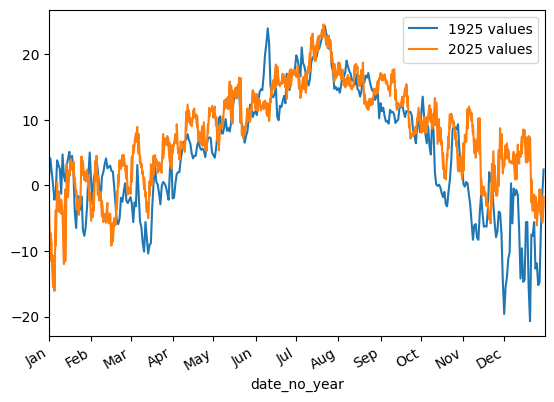

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import datetime as dt


endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters_historic = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D) ",
    "referencetime": "1925-01-01/1925-12-31",
}

historic_response = requests.get(endpoint, parameters_historic, auth=(client_id, ""))
json_historic_data = historic_response.json()
data_historic = json_historic_data["data"]

# print(json.dumps(json_data, indent=4))

historic_values = pd.DataFrame()

frames_historic = []
for e in range(len(data_historic)):
    row = pd.DataFrame(data_historic[e]["observations"])
    row["referencetime"] = pd.to_datetime(data_historic[e]["referenceTime"])
    row["sources"] = data_historic[e]["sourceId"]
    frames_historic.append(row)
historic_values = pd.concat(frames_historic, ignore_index=True)

values['date_no_year'] = pd.to_datetime(
    {'year': 2000, 'month': values['referencetime'].dt.month, 'day': values['referencetime'].dt.day}
)
historic_values['date_no_year'] = pd.to_datetime(
    {'year': 2000, 'month': historic_values['referencetime'].dt.month, 'day': historic_values['referencetime'].dt.day}
)

ax = plt.subplot()

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

historic_values.plot(x="date_no_year", y="value", ax=ax, label="1925 values", xlim=("2000-01-01", "2000-12-31"))
values.plot(x="date_no_year", y="value", ax=ax, label="2025 values", xlim=("2000-01-01", "2000-12-31"))


Task 4: Heatwaves
The next task is to look for heatwaves in Ås in 2025
In Norway a heatwave is defined as a consecutive period of five or more day where
the
max temperature is >= 27 degrees Celcius.
Note that you need max temperature here, not mean
Max temperature is coded as max(air_temperature P1D)
met.no article about heatwaves (only in Norwegian)
Write a function that count the number of heatwaves in a year.
The function should write a summary to a yml file, formatted as the example file
Write the function so that it will work with any station name/id and year

dates:
- 2025-07-23 - 2025-07-30
- 2025-08-13 - 2025-08-22
station_id: SN17850
station_name: "\xC5s"
year: 2025

In [ ]:
def heat_wave_finder(station_id, year):

    with open("heat_wave.yml", mode="w+") as f:

        station_endpoint = f"https://frost.met.no/sources/v0.jsonld?ids={station_id}"
        station_response = requests.get(station_endpoint, auth=(client_id, ""))
        json_station_data = station_response.json()
        # print(json_station_data["data"])
        station_name = json_station_data["data"][0]["name"]

        endpoint = "https://frost.met.no/observations/v0.jsonld"
        parameters_heat_wave = {
            "sources": station_id,
            "elements": "max(air_temperature P1D)",
            "referencetime": f"{year}-01-01/{year}-12-31",
        }

        heat_wave_response = requests.get(endpoint, parameters_heat_wave, auth=(client_id, ""))
        json_heat_wave_data = heat_wave_response.json()
        data_heat_wave = json_heat_wave_data["data"]
        # print(data_heat_wave)
        # Needs to keep track of the dates, stationID, name and year for the heatwaves
        heat_wave_start = ""
        HEAT_WAVE_THRESHOLD = 27
        day_counter = 0
        f.write("dates:" + "\n")
        for item in data_heat_wave:
            # print(item["referenceTime"])
            today_is_heat_wave_day = False
            for observation in item["observations"]:
                # print(observation)
                # print(observation["value"])
                if float(observation["value"]) >= HEAT_WAVE_THRESHOLD:
                    # print(observation["value"])
                    today_is_heat_wave_day = True
                    break
            if today_is_heat_wave_day:
                day_counter += 1
            else:
                if day_counter >= 5:
                    # print("heatwave")
                    current_date = pd.to_datetime(item["referenceTime"])
                    # end date: today - 1
                    print(current_date)
                    end_date = current_date - pd.Timedelta(days=1)
                    # print(end_date)
                    # start date: today - counter - 1
                    start_date = current_date - pd.Timedelta(days=(day_counter))
                    f.write(f"- {start_date} - {end_date} \n")
                day_counter = 0
        f.write(f"""station_id: {station_id}
station_name: {station_name}
year: {year}""")


heat_wave_finder("SN17850", 2025)

[{'sourceId': 'SN17850:0', 'referenceTime': '2025-01-01T00:00:00.000Z', 'observations': [{'elementId': 'max(air_temperature P1D)', 'value': -3.4, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT0H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1'}, {'elementId': 'max(air_temperature P1D)', 'value': -3, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT18H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 0}]}, {'sourceId': 'SN17850:0', 'referenceTime': '2025-01-02T00:00:00.000Z', 'observations': [{'elementId': 'max(air_temperature P1D)', 'value': -5.2, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT0H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1'}, {'element

Task 5: Moving average temperature
Write a function that calculates the 7-day moving average for temperature
Use this function on the 2025 mean temperature you collected in task 1
Make a plot showing the moving average as a line and the daily temperature as
points

-5.2
[-5.2]
-8.35
[-5.2, -11.5]
-8.533333333333333
[-5.2, -11.5, -8.9]
-10.275
[-5.2, -11.5, -8.9, -15.5]
-10.72
[-5.2, -11.5, -8.9, -15.5, -12.5]
-9.566666666666666
[-5.2, -11.5, -8.9, -15.5, -12.5, -3.8]
-8.142857142857142
[-5.2, -11.5, -8.9, -15.5, -12.5, -3.8, 0.4]
-7.971428571428571
[-11.5, -8.9, -15.5, -12.5, -3.8, 0.4, -4]
-6.671428571428571
[-8.9, -15.5, -12.5, -3.8, 0.4, -4, -2.4]
-6.014285714285714
[-15.5, -12.5, -3.8, 0.4, -4, -2.4, -4.3]
-4.457142857142856
[-12.5, -3.8, 0.4, -4, -2.4, -4.3, -4.6]
-4.385714285714286
[-3.8, 0.4, -4, -2.4, -4.3, -4.6, -12]
-3.9285714285714284
[0.4, -4, -2.4, -4.3, -4.6, -12, -0.6]
-3.914285714285714
[-4, -2.4, -4.3, -4.6, -12, -0.6, 0.5]
-3.414285714285714
[-2.4, -4.3, -4.6, -12, -0.6, 0.5, -0.5]
-2.742857142857143
[-4.3, -4.6, -12, -0.6, 0.5, -0.5, 2.3]
-1.5571428571428574
[-4.6, -12, -0.6, 0.5, -0.5, 2.3, 4]
-0.5571428571428573
[-12, -0.6, 0.5, -0.5, 2.3, 4, 2.4]
1.4142857142857144
[-0.6, 0.5, -0.5, 2.3, 4, 2.4, 1.8]
1.5142857142857142
[0.5,

<Axes: xlabel='referencetime', ylabel='value'>

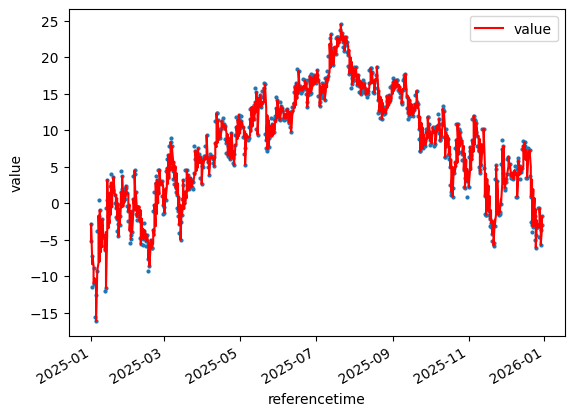

In [ ]:
endpoint_avg = "https://frost.met.no/observations/v0.jsonld"
parameters_avg = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

response_avg = requests.get(endpoint_avg, parameters_avg, auth=(client_id, ""))
json_data_avg = response_avg.json()
data_avg = json_data_avg["data"]

# print(json.dumps(json_data, indent=4))

values_avg = pd.DataFrame()

avg_frames = []
avg_values = []
frames = []
for e in range(len(data_avg)):
    row = pd.DataFrame(data_avg[e]["observations"])
    row["referencetime"] = pd.to_datetime(data_avg[e]["referenceTime"])
    row["sources"] = data_avg[e]["sourceId"]
    frames.append(row)

    val = data_avg[e]["observations"][0]["value"]
    avg_values.append(val)
    last_seven = avg_values[-7:]
    last_seven_avg = sum(last_seven)/len(last_seven)
    # print(last_seven_avg)
    # print(last_seven)
    data_avg[e]["observations"][0]["value"] = last_seven_avg
    avg_row = pd.DataFrame(data_avg[e]["observations"])
    avg_row["referencetime"] = pd.to_datetime(data_avg[e]["referenceTime"])
    avg_row["sources"] = data_avg[e]["sourceId"]
    avg_frames.append(avg_row)
values_avg = pd.concat(frames, ignore_index=True)
new_stuff = pd.concat(avg_frames, ignore_index=True)

ax = plt.subplot()
values_avg.plot.scatter(x="referencetime", y="value", s=4, ax=ax)
new_stuff.plot(x="referencetime", y="value", ax=ax, color="red")
